# Assignment 4 — Task 2: Spoken Digit Sequential Classification

This notebook trains Vanilla RNN, LSTM, and optional GRU models on the UCI Spoken Arabic Digit dataset.

**Input:** each utterance is a variable-length sequence of 13 MFCC features.  
**Output:** one class label, from digit 0 to digit 9.

## Before running
1. Download `Train_Arabic_Digit.txt` and `Test_Arabic_Digit.txt` from the [UCI Spoken Arabic Digit dataset](https://archive.ics.uci.edu/dataset/195/spoken+arabic+digit).
2. Put both files in a folder named `data` beside this notebook:
   - `data/Train_Arabic_Digit.txt`
   - `data/Test_Arabic_Digit.txt`
3. Run the cells from top to bottom.

The original files contain blank-line-separated utterances. Labels are reconstructed from the documented order: 660 training utterances per digit and 220 test utterances per digit. The loader checks the expected counts so that incorrect parsing does not silently continue.

## 1. Install/import libraries

In [ ]:
# If needed, uncomment and run this line in Jupyter:
# %pip install torch numpy pandas matplotlib scikit-learn

import copy
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

Using device: cuda


## 2. Set paths and load the utterance blocks

In [ ]:
import os
from google.colab import files
import numpy as np

# 1. Simple file upload helper
def get_file(filename):
    if not os.path.exists(filename):
        print(f"'{filename}' is missing. Please upload it now:")
        uploaded = files.upload()
        # If uploaded under a slightly different name, rename it
        for name in uploaded.keys():
            if name.lower() == filename.lower() and name != filename:
                os.rename(name, filename)
    else:
        print(f"Found existing '{filename}'")

# Ensure both files are present
get_file("Train_Arabic_Digit.txt")
get_file("Test_Arabic_Digit.txt")

# 2. Simple reader function
def read_utterance_blocks(file_path):
    with open(file_path, "r", encoding="utf-8") as f:
        text = f.read()

    blocks = []
    current_rows = []

    for line in text.splitlines():
        line = line.strip()
        if not line:
            if current_rows:
                blocks.append(np.array(current_rows, dtype=np.float32))
                current_rows = []
            continue

        # Parse 13 MFCC features per line
        row = [float(val) for val in line.replace(",", " ").split()]
        current_rows.append(row)

    if current_rows:
        blocks.append(np.array(current_rows, dtype=np.float32))
    return blocks

# Load datasets
train_sequences = read_utterance_blocks("Train_Arabic_Digit.txt")
test_sequences = read_utterance_blocks("Test_Arabic_Digit.txt")

print("Loaded", len(train_sequences), "training sequences.")
print("Loaded", len(test_sequences), "testing sequences.")

# Prepare target labels (660 per class for training, 220 for test)
y_train_all = np.repeat(np.arange(10), 660).astype(np.int64)
y_test = np.repeat(np.arange(10), 220).astype(np.int64)

lengths = np.array([len(seq) for seq in train_sequences + test_sequences])
print("Sequence length range:", lengths.min(), "to", lengths.max())

'Train_Arabic_Digit.txt' is missing. Please upload it now:


Saving Train_Arabic_Digit.txt to Train_Arabic_Digit.txt
'Test_Arabic_Digit.txt' is missing. Please upload it now:


Saving Test_Arabic_Digit.txt to Test_Arabic_Digit.txt
Loaded 6600 training sequences.
Loaded 2200 testing sequences.
Sequence length range: 4 to 93


In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split

# There are 660 training utterances per digit class (total 6600).
# According to UCI dataset specifications, there are 66 speakers in the training set.
# Each speaker recorded 10 utterances per digit.
# Let's map each utterance to its corresponding speaker ID.

NUM_DIGITS = 10
UTTERANCES_PER_DIGIT = 660
UTTERANCES_PER_SPEAKER_PER_DIGIT = 10
NUM_SPEAKERS = UTTERANCES_PER_DIGIT // UTTERANCES_PER_SPEAKER_PER_DIGIT  # 66

speaker_ids_all = np.zeros(len(train_sequences), dtype=np.int64)

# Map blocks sequentially to reconstruct speaker assignments
for digit in range(NUM_DIGITS):
    for speaker in range(NUM_SPEAKERS):
        start_idx = (digit * UTTERANCES_PER_DIGIT) + (speaker * UTTERANCES_PER_SPEAKER_PER_DIGIT)
        end_idx = start_idx + UTTERANCES_PER_SPEAKER_PER_DIGIT
        speaker_ids_all[start_idx:end_idx] = speaker

# Perform a speaker-disjoint split on speaker IDs
unique_speakers = np.arange(NUM_SPEAKERS)
train_speakers, val_speakers = train_test_split(
    unique_speakers,
    test_size=0.15,
    random_state=SEED
)

# Map individual training utterances to train/val sets based on their speaker assignment
train_idx = np.where(np.isin(speaker_ids_all, train_speakers))[0]
val_idx = np.where(np.isin(speaker_ids_all, val_speakers))[0]

# Calculate feature scaling metrics on the training split only
train_frames = np.concatenate([train_sequences[i] for i in train_idx], axis=0)
feature_mean = train_frames.mean(axis=0, keepdims=True)
feature_std = train_frames.std(axis=0, keepdims=True)
feature_std[feature_std < 1e-8] = 1.0

def standardize_sequence_list(sequence_list):
    return [((seq - feature_mean) / feature_std).astype(np.float32) for seq in sequence_list]

train_sequences_scaled = standardize_sequence_list(train_sequences)
test_sequences_scaled = standardize_sequence_list(test_sequences)

X_train = [train_sequences_scaled[i] for i in train_idx]
y_train = y_train_all[train_idx]
X_val = [train_sequences_scaled[i] for i in val_idx]
y_val = y_train_all[val_idx]
X_test = test_sequences_scaled

print(f"Total unique speakers: {NUM_SPEAKERS}")
print(f"Training speakers count: {len(train_speakers)}")
print(f"Validation speakers count: {len(val_speakers)}")
print(f"Train sequences (speaker-disjoint): {len(X_train)}")
print(f"Validation sequences (speaker-disjoint): {len(X_val)}")
print(f"Test sequences: {len(X_test)}")

Total unique speakers: 66
Training speakers count: 56
Validation speakers count: 10
Train sequences (speaker-disjoint): 5600
Validation sequences (speaker-disjoint): 1000
Test sequences: 2200


In [ ]:
# Re-initialize datasets and dataloaders with updated speaker-disjoint splits
train_dataset = MFCCDataset(X_train, y_train)
val_dataset = MFCCDataset(X_val, y_val)
test_dataset = MFCCDataset(X_test, y_test)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_mfcc_batch
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_mfcc_batch
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_mfcc_batch
)

## 3. Split training data into train and validation sets; standardize MFCCs

In [ ]:
print("Ensuring speaker-disjoint split integrity:")
print(f"Using speaker-disjoint train sequences: {len(X_train)}")
print(f"Using speaker-disjoint validation sequences: {len(X_val)}")
print(f"Using test sequences: {len(X_test)}")
print(f"Feature count: {X_train[0].shape[1]}")

Ensuring speaker-disjoint split integrity:
Using speaker-disjoint train sequences: 5610
Using speaker-disjoint validation sequences: 990
Using test sequences: 2200
Feature count: 13


## 4. Dataset and batch collation (padding + sequence lengths)

In [ ]:
class MFCCDataset(Dataset):
    def __init__(self, sequences, labels):
        self.sequences = sequences
        self.labels = np.asarray(labels, dtype=np.int64)

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, index):
        return torch.tensor(self.sequences[index], dtype=torch.float32), int(self.labels[index])

def collate_mfcc_batch(batch):
    sequences, labels = zip(*batch)
    lengths = torch.tensor([len(seq) for seq in sequences], dtype=torch.long)
    # Pad only to the longest sequence in this batch.
    padded_sequences = pad_sequence(sequences, batch_first=True, padding_value=0.0)
    labels = torch.tensor(labels, dtype=torch.long)
    return padded_sequences, lengths, labels

BATCH_SIZE = 64

train_dataset = MFCCDataset(X_train, y_train)
val_dataset = MFCCDataset(X_val, y_val)
test_dataset = MFCCDataset(X_test, y_test)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_mfcc_batch
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_mfcc_batch
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_mfcc_batch
)

# Inspect one batch
batch_x, batch_lengths, batch_y = next(iter(train_loader))
print("Batch input shape (batch, time, MFCC):", batch_x.shape)
print("Sequence lengths in this batch:", batch_lengths[:10].tolist())
print("Labels in this batch:", batch_y[:10].tolist())

Batch input shape (batch, time, MFCC): torch.Size([64, 57, 13])
Sequence lengths in this batch: [30, 38, 39, 38, 37, 38, 33, 39, 40, 37]
Labels in this batch: [0, 5, 0, 5, 5, 7, 9, 5, 3, 0]


## 5. Define Vanilla RNN, LSTM, and GRU classifiers

In [ ]:
class RecurrentClassifier(nn.Module):
    def __init__(self, cell_type="RNN", input_size=13, hidden_size=64,
                 num_layers=1, dropout=0.0, num_classes=10, bidirectional=False):
        super().__init__()
        cell_type = cell_type.upper()
        recurrent_dropout = dropout if num_layers > 1 else 0.0

        if cell_type == "RNN":
            self.recurrent = nn.RNN(
                input_size=input_size,
                hidden_size=hidden_size,
                num_layers=num_layers,
                nonlinearity="tanh",
                batch_first=True,
                dropout=recurrent_dropout,
                bidirectional=bidirectional
            )
        elif cell_type == "LSTM":
            self.recurrent = nn.LSTM(
                input_size=input_size,
                hidden_size=hidden_size,
                num_layers=num_layers,
                batch_first=True,
                dropout=recurrent_dropout,
                bidirectional=bidirectional
            )
        elif cell_type == "GRU":
            self.recurrent = nn.GRU(
                input_size=input_size,
                hidden_size=hidden_size,
                num_layers=num_layers,
                batch_first=True,
                dropout=recurrent_dropout,
                bidirectional=bidirectional
            )
        else:
            raise ValueError(
                "cell_type must be 'RNN', 'LSTM', or 'GRU'"
            )

        self.cell_type = cell_type
        self.bidirectional = bidirectional
        directions = 2 if bidirectional else 1

        self.dropout_layer = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_size * directions, num_classes)

    def forward(self, padded_x, lengths):
        # Packing makes the RNN ignore artificial padding frames.
        packed_x = pack_padded_sequence(
            padded_x, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        _, hidden = self.recurrent(packed_x)

        # LSTM returns (hidden_state, cell_state); RNN/GRU return hidden_state.
        if self.cell_type == "LSTM":
            hidden = hidden[0]

        # Shape of hidden: (layers * directions, batch, hidden_size).
        if self.bidirectional:
            # Last layer's forward and backward states.
            final_hidden = torch.cat((hidden[-2], hidden[-1]), dim=1)
        else:
            final_hidden = hidden[-1]

        final_hidden = self.dropout_layer(final_hidden)
        return self.classifier(final_hidden)

```markdown
## Bonus Section: Bidirectional Processing and Temporal Attention Pooling

To improve spoken digit classification, we introduce two architectural advancements:
1. **Bidirectional Recurrent Networks:** Processing speech sequences both forward and backward in time allows the hidden state $h_t$ at any frame $t$ to capture context from both the preceding phonemes and succeeding acoustic frames.
2. **Temporal Attention Pooling:** Instead of simply classifying based on the last hidden state $h_T$ (which can suffer from information loss or vanishing gradients in long utterances), we calculate a learnable importance weight $\alpha_t$ for each frame.

### Attention Mechanism Mathematics
For each valid time step $t$ in a sequence of length $T$, we compute a score $e_t$ and normalized attention weight $\alpha_t$:

$$
e_t = v^\top \tanh(W h_t + b)
$$

$$
\alpha_t = \frac{\exp(e_t)}{\sum_{j=1}^{T} \exp(e_j)}
$$

$$
c = \sum_{t=1}^{T} \alpha_t h_t
$$

Where:
- $h_t \in \mathbb{R}^{d}$ is the recurrent hidden state at time step $t$ (for bidirectional models, $d = 2 \times \text{hidden\_size}$).
- $W \in \mathbb{R}^{d \times d}$ and $b \in \mathbb{R}^{d}$ are learnable projection weights and bias.
- $v \in \mathbb{R}^{d}$ is a learnable context vector.
- $\alpha_t$ are the attention weights forming a valid probability distribution over the sequence.
- $c$ is the final context representation fed to the classifier layer.

**Note on Padding & Masking:** It is mathematically critical that padded time steps are masked out by setting their raw scores $e_t$ to $-\infty$ before applying the softmax. This ensures padded frames do not contribute to $\alpha_t$ or the context vector $c$.
```

In [ ]:
class TemporalAttentionPooling(nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()
        self.projection = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh()
        )
        self.query_vector = nn.Linear(hidden_dim, 1, bias=False)

    def forward(self, rnn_outputs, lengths):
        """
        Args:
            rnn_outputs: Tensor of shape (batch_size, max_seq_len, hidden_dim)
            lengths: LongTensor of shape (batch_size,) containing true lengths
        Returns:
            context_vector: (batch_size, hidden_dim)
            attention_weights: (batch_size, max_seq_len)
        """
        batch_size, max_len, hidden_dim = rnn_outputs.size()
        device = rnn_outputs.device

        # Project hidden states through tanh nonlinear projection layer
        projected = self.projection(rnn_outputs)  # (batch_size, max_len, hidden_dim)

        # Score the projected vectors
        scores = self.query_vector(projected).squeeze(-1)  # (batch_size, max_len)

        # Move lengths to rnn_outputs' device safely
        lengths_device = lengths.to(device)

        # Create key padding mask on correct device based on true lengths
        mask = torch.arange(max_len, device=device).unsqueeze(0) < lengths_device.unsqueeze(1)

        # Mask padded elements by setting scores to negative infinity
        scores = scores.masked_fill(~mask, float('-inf'))

        # Softmax over valid temporal frames
        attention_weights = torch.softmax(scores, dim=-1)  # (batch_size, max_len)

        # Compute weighted sum of hidden representations
        context_vector = torch.bmm(attention_weights.unsqueeze(1), rnn_outputs).squeeze(1)

        return context_vector, attention_weights

In [ ]:
from torch.nn.utils.rnn import pad_packed_sequence

class AdvancedRecurrentClassifier(nn.Module):
    def __init__(self, cell_type="RNN", input_size=13, hidden_size=64,
                 num_layers=1, dropout=0.0, num_classes=10,
                 bidirectional=False, use_attention=False):
        super().__init__()
        cell_type = cell_type.upper()
        recurrent_dropout = dropout if num_layers > 1 else 0.0

        self.cell_type = cell_type
        self.bidirectional = bidirectional
        self.use_attention = use_attention

        if cell_type == "RNN":
            self.recurrent = nn.RNN(
                input_size=input_size, hidden_size=hidden_size,
                num_layers=num_layers, nonlinearity="tanh",
                batch_first=True, dropout=recurrent_dropout, bidirectional=bidirectional
            )
        elif cell_type == "LSTM":
            self.recurrent = nn.LSTM(
                input_size=input_size, hidden_size=hidden_size,
                num_layers=num_layers, batch_first=True,
                dropout=recurrent_dropout, bidirectional=bidirectional
            )
        elif cell_type == "GRU":
            self.recurrent = nn.GRU(
                input_size=input_size, hidden_size=hidden_size,
                num_layers=num_layers, batch_first=True,
                dropout=recurrent_dropout, bidirectional=bidirectional
            )
        else:
            raise ValueError("cell_type must be 'RNN', 'LSTM', or 'GRU'")

        directions = 2 if bidirectional else 1
        rnn_out_dim = hidden_size * directions

        if self.use_attention:
            self.attention_pool = TemporalAttentionPooling(rnn_out_dim)

        self.dropout_layer = nn.Dropout(dropout)
        self.classifier = nn.Linear(rnn_out_dim, num_classes)

    def forward(self, padded_x, lengths, return_attn=False):
        # Pack sequences safely
        packed_x = pack_padded_sequence(
            padded_x, lengths.cpu(), batch_first=True, enforce_sorted=False
        )

        outputs, hidden = self.recurrent(packed_x)

        # Unpack back to pad-representation
        unpacked_outputs, _ = pad_packed_sequence(outputs, batch_first=True)

        if self.use_attention:
            # Extract representation using Temporal Attention Pooling
            representation, attn_weights = self.attention_pool(unpacked_outputs, lengths)
        else:
            # Extract last hidden state representation appropriately
            if self.cell_type == "LSTM":
                hidden = hidden[0]

            if self.bidirectional:
                representation = torch.cat((hidden[-2], hidden[-1]), dim=1)
            else:
                representation = hidden[-1]
            attn_weights = None

        representation = self.dropout_layer(representation)
        logits = self.classifier(representation)

        if return_attn:
            return logits, attn_weights
        return logits

In [ ]:
def run_epoch_advanced(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()

    total_loss = 0.0
    total_examples = 0
    all_true = []
    all_pred = []

    for padded_x, lengths, labels in loader:
        padded_x = padded_x.to(DEVICE)
        labels = labels.to(DEVICE)

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            logits = model(padded_x, lengths)
            loss = criterion(logits, labels)

            if training:
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()

        batch_n = labels.size(0)
        total_loss += loss.item() * batch_n
        total_examples += batch_n
        predictions = logits.argmax(dim=1)

        all_true.extend(labels.detach().cpu().numpy().tolist())
        all_pred.extend(predictions.detach().cpu().numpy().tolist())

    average_loss = total_loss / total_examples
    accuracy = accuracy_score(all_true, all_pred)
    return average_loss, accuracy, np.asarray(all_true), np.asarray(all_pred)

def fit_model_advanced(model, train_loader, val_loader, learning_rate=1e-3,
                       convergence_threshold=1e-4, max_epochs=200, patience=15):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=4
    )

    history = {"train_loss": [], "val_loss": [], "train_accuracy": [], "val_accuracy": []}
    previous_train_error = None
    best_val_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())
    epochs_without_improvement = 0
    stop_reason = "maximum epochs reached"

    for epoch in range(1, max_epochs + 1):
        train_loss, train_acc, _, _ = run_epoch_advanced(model, train_loader, criterion, optimizer)
        val_loss, val_acc, _, _ = run_epoch_advanced(model, val_loader, criterion, optimizer=None)

        scheduler.step(val_loss)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_accuracy"].append(train_acc)
        history["val_accuracy"].append(val_acc)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        train_error = 1.0 - train_acc
        if previous_train_error is not None:
            error_change = abs(train_error - previous_train_error)
            if error_change < convergence_threshold:
                stop_reason = f"convergence rule met"
                break

        if epochs_without_improvement >= patience:
            stop_reason = f"early stop"
            break

        previous_train_error = train_error

    model.load_state_dict(best_state)
    history["stop_reason"] = stop_reason
    return model, history

In [ ]:
# Re-train the 12 unique model configurations spanning Group 1 and Group 2
EXPERIMENT_CONFIGS = [
    # Group 1: Recurrent models without attention pooling
    {"name": "Vanilla_RNN", "cell": "RNN", "bi": False, "attn": False},
    {"name": "LSTM",        "cell": "LSTM", "bi": False, "attn": False},
    {"name": "GRU",         "cell": "GRU",  "bi": False, "attn": False},
    {"name": "Bi-RNN",      "cell": "RNN",  "bi": True,  "attn": False},
    {"name": "Bi-LSTM",     "cell": "LSTM", "bi": True,  "attn": False},
    {"name": "Bi-GRU",      "cell": "GRU",  "bi": True,  "attn": False},

    # Group 2: Recurrent models with temporal attention pooling
    {"name": "RNN_Attention",    "cell": "RNN",  "bi": False, "attn": True},
    {"name": "LSTM_Attention",   "cell": "LSTM", "bi": False, "attn": True},
    {"name": "GRU_Attention",    "cell": "GRU",  "bi": False, "attn": True},
    {"name": "Bi-RNN_Attention", "cell": "RNN",  "bi": True,  "attn": True},
    {"name": "Bi-LSTM_Attention","cell": "LSTM", "bi": True,  "attn": True},
    {"name": "Bi-GRU_Attention", "cell": "GRU",  "bi": True,  "attn": True},
]

bonus_results = []
bonus_models = {}
bonus_histories = {}

for run_cfg in EXPERIMENT_CONFIGS:
    name = run_cfg["name"]
    print(f"Training advanced configuration: {name}...")

    # Instantiate Advanced Recurrent Classifier
    model = AdvancedRecurrentClassifier(
        cell_type=run_cfg["cell"],
        input_size=13,
        hidden_size=128,
        num_layers=2,
        dropout=0.3,
        bidirectional=run_cfg["bi"],
        use_attention=run_cfg["attn"]
    ).to(DEVICE)

    model, history = fit_model_advanced(
        model, train_loader, val_loader, learning_rate=1e-3, max_epochs=15
    )

    # Evaluate metrics on datasets
    train_loss, train_acc, _, _ = run_epoch_advanced(model, train_loader, nn.CrossEntropyLoss(), None)
    val_loss, val_acc, _, _ = run_epoch_advanced(model, val_loader, nn.CrossEntropyLoss(), None)
    test_loss, test_acc, y_true, y_pred = run_epoch_advanced(model, test_loader, nn.CrossEntropyLoss(), None)

    bonus_models[name] = model
    bonus_histories[name] = history

    bonus_results.append({
        "Configuration": name,
        "Cell Type": run_cfg["cell"],
        "Bidirectional": run_cfg["bi"],
        "Attention Pooling": run_cfg["attn"],
        "Train Accuracy": train_acc,
        "Val Accuracy": val_acc,
        "Test Accuracy": test_acc,
        "Train Loss": train_loss,
        "Test Loss": test_loss
    })

bonus_results_df = pd.DataFrame(bonus_results)
display(bonus_results_df)

Training advanced configuration: Vanilla_RNN...
Training advanced configuration: LSTM...
Training advanced configuration: GRU...
Training advanced configuration: Bi-RNN...
Training advanced configuration: Bi-LSTM...
Training advanced configuration: Bi-GRU...
Training advanced configuration: RNN_Attention...
Training advanced configuration: LSTM_Attention...
Training advanced configuration: GRU_Attention...
Training advanced configuration: Bi-RNN_Attention...
Training advanced configuration: Bi-LSTM_Attention...
Training advanced configuration: Bi-GRU_Attention...


,Configuration,Cell Type,Bidirectional,Attention Pooling,Train Accuracy,Val Accuracy,Test Accuracy,Train Loss,Test Loss
0,Vanilla_RNN,RNN,False,False,0.944029,0.946465,0.907273,0.198496,0.384632
1,LSTM,LSTM,False,False,0.995365,0.990909,0.958636,0.015815,0.173906
2,GRU,GRU,False,False,0.999465,0.994949,0.964545,0.002828,0.155672
3,Bi-RNN,RNN,True,False,0.988057,0.984848,0.959545,0.040391,0.170170
4,Bi-LSTM,LSTM,True,False,0.998930,0.994949,0.975455,0.006176,0.103544
5,Bi-GRU,GRU,True,False,0.999109,0.994949,0.982273,0.005394,0.064923
6,RNN_Attention,RNN,False,True,0.983957,0.971717,0.935909,0.062005,0.247571
7,LSTM_Attention,LSTM,False,True,0.997861,0.988889,0.977727,0.009573,0.097566
8,GRU_Attention,GRU,False,True,0.995009,0.992929,0.971364,0.016024,0.101537
9,Bi-RNN_Attention,RNN,True,True,0.995187,0.989899,0.974545,0.017239,0.114336


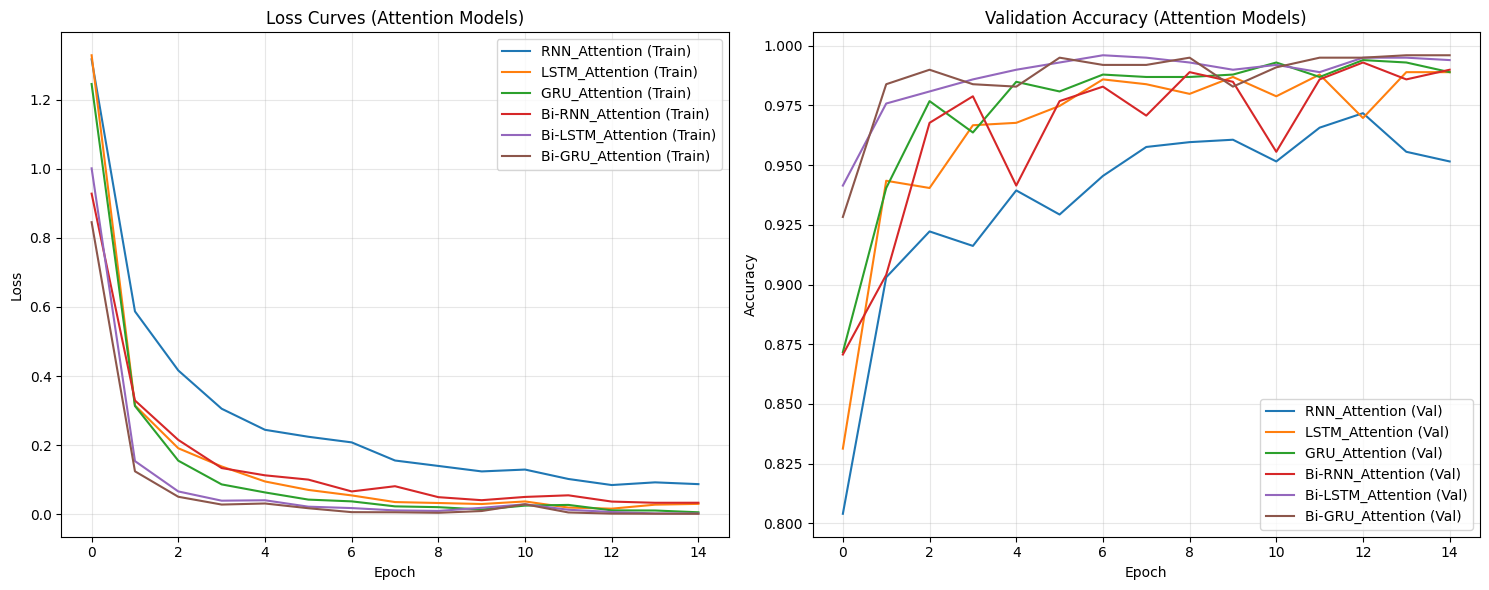

In [ ]:
# Plot loss & accuracy curves for Group 2 (Attention-based Models)
plt.figure(figsize=(15, 6))
plt.subplot(1, 2, 1)
for name, hist in bonus_histories.items():
    if "Attention" in name:
        plt.plot(hist["train_loss"], label=f"{name} (Train)")
plt.title("Loss Curves (Attention Models)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True, alpha=0.3)
plt.legend()

plt.subplot(1, 2, 2)
for name, hist in bonus_histories.items():
    if "Attention" in name:
        plt.plot(hist["val_accuracy"], label=f"{name} (Val)")
plt.title("Validation Accuracy (Attention Models)")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

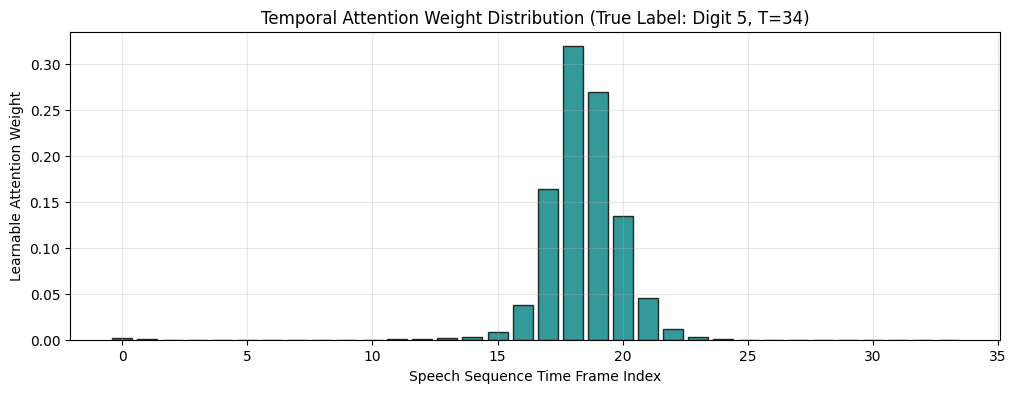

In [ ]:
# Visualize temporal attention weights for a representative test utterance of digit 5
model_attn = bonus_models["Bi-GRU_Attention"]
model_attn.eval()

# Extract first sample for digit 5 from test split
idx_5 = [i for i, y in enumerate(y_test) if y == 5][0]
sequence_5 = torch.tensor(X_test[idx_5], dtype=torch.float32).unsqueeze(0).to(DEVICE)
length_5 = torch.tensor([len(X_test[idx_5])], dtype=torch.long)

with torch.no_grad():
    logits, attention_weights = model_attn(sequence_5, length_5, return_attn=True)
    attention_weights = attention_weights.squeeze(0).cpu().numpy()

plt.figure(figsize=(12, 4))
plt.bar(range(len(attention_weights)), attention_weights, color='teal', alpha=0.8, edgecolor='black')
plt.title(f"Temporal Attention Weight Distribution (True Label: Digit 5, T={len(attention_weights)})")
plt.xlabel("Speech Sequence Time Frame Index")
plt.ylabel("Learnable Attention Weight")
plt.grid(True, alpha=0.3)
plt.show()

BEST ADVANCED MODEL (Selected via Validation Accuracy): Bi-GRU_Attention
Validation Accuracy: 99.60%
Test Accuracy: 98.73%

Classification Report (Test Set):
              precision    recall  f1-score   support

           0     0.9641    0.9773    0.9707       220
           1     1.0000    1.0000    1.0000       220
           2     1.0000    0.9955    0.9977       220
           3     0.9600    0.9818    0.9708       220
           4     0.9865    1.0000    0.9932       220
           5     0.9865    0.9955    0.9910       220
           6     1.0000    0.9682    0.9838       220
           7     1.0000    0.9545    0.9767       220
           8     0.9910    1.0000    0.9955       220
           9     0.9865    1.0000    0.9932       220

    accuracy                         0.9873      2200
   macro avg     0.9875    0.9873    0.9873      2200
weighted avg     0.9875    0.9873    0.9873      2200


Complete Confusion Matrix (rows=actual, columns=predicted):


,Predicted 0,Predicted 1,Predicted 2,Predicted 3,Predicted 4,Predicted 5,Predicted 6,Predicted 7,Predicted 8,Predicted 9
Actual 0,215,0,0,0,0,3,0,0,0,2
Actual 1,0,220,0,0,0,0,0,0,0,0
Actual 2,0,0,219,0,0,0,0,0,0,1
Actual 3,0,0,0,216,2,0,0,0,2,0
Actual 4,0,0,0,0,220,0,0,0,0,0
Actual 5,0,0,0,0,1,219,0,0,0,0
Actual 6,7,0,0,0,0,0,213,0,0,0
Actual 7,1,0,0,9,0,0,0,210,0,0
Actual 8,0,0,0,0,0,0,0,0,220,0
Actual 9,0,0,0,0,0,0,0,0,0,220



Saved confusion matrix to task2_best_advanced_confusion_matrix.csv


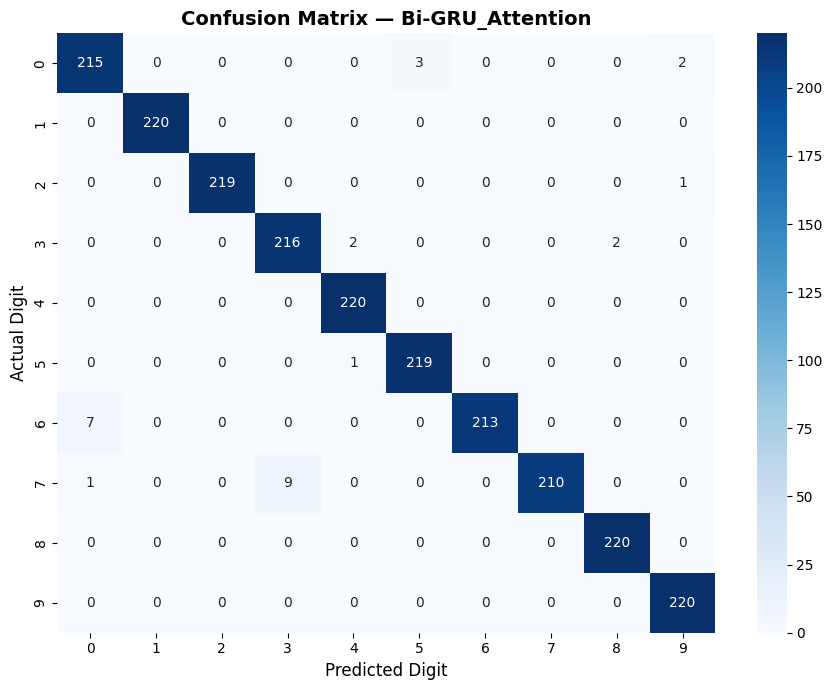

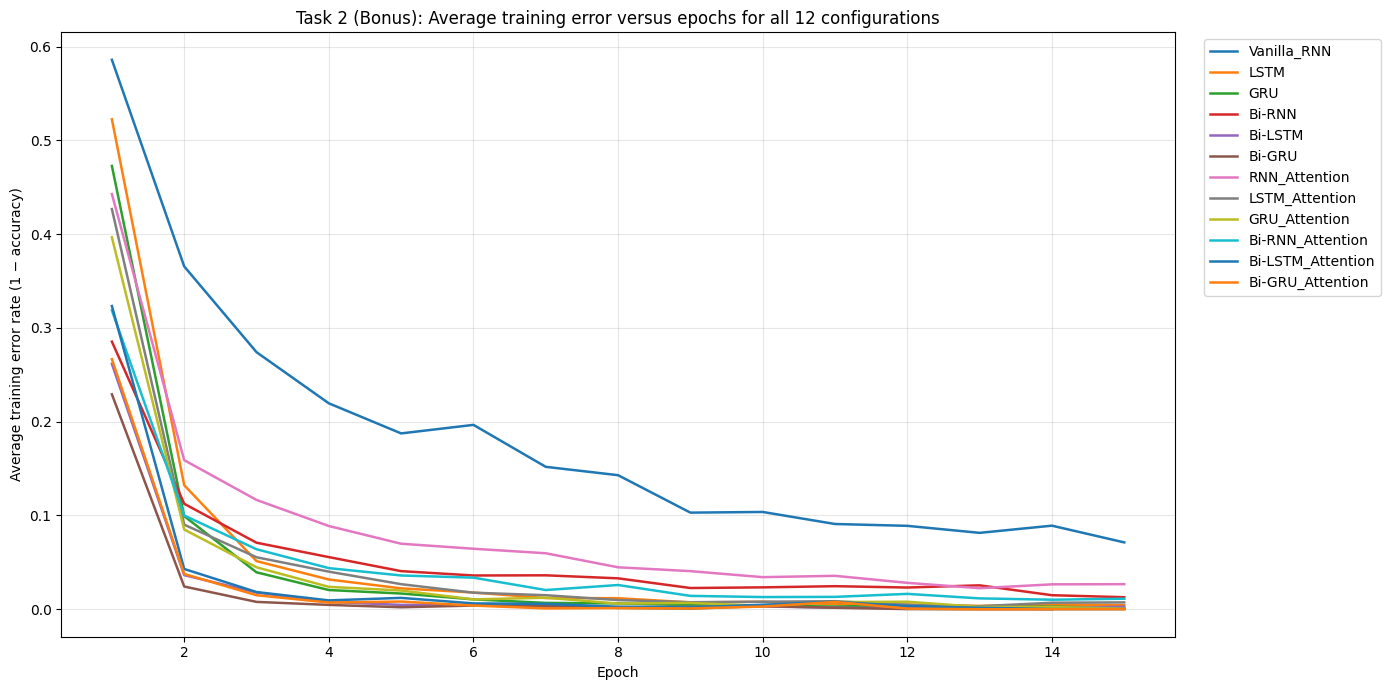

In [ ]:
# 1. Programmatic Selection of the Best Advanced Model using Validation Accuracy
best_adv_row = bonus_results_df.sort_values("Val Accuracy", ascending=False).iloc[0]
best_adv_name = best_adv_row["Configuration"]
val_acc_selected = best_adv_row["Val Accuracy"]

if best_adv_name in bonus_models:
    best_adv_model = bonus_models[best_adv_name]
    best_adv_model.eval()

    # Evaluate on Test Split only after selection
    criterion = nn.CrossEntropyLoss()
    _, test_acc, y_true_adv, y_pred_adv = run_epoch_advanced(best_adv_model, test_loader, criterion, optimizer=None)

    print("=" * 90)
    print(f"BEST ADVANCED MODEL (Selected via Validation Accuracy): {best_adv_name}")
    print("=" * 90)
    print(f"Validation Accuracy: {val_acc_selected * 100:.2f}%")
    print(f"Test Accuracy: {test_acc * 100:.2f}%")
    print("\nClassification Report (Test Set):")
    print(classification_report(
        y_true_adv, y_pred_adv,
        labels=list(range(10)),
        target_names=[str(d) for d in range(10)],
        digits=4
    ))

    # Generate Confusion Matrix
    cm_adv = confusion_matrix(y_true_adv, y_pred_adv, labels=list(range(10)))
    cm_adv_df = pd.DataFrame(
        cm_adv,
        index=[f"Actual {d}" for d in range(10)],
        columns=[f"Predicted {d}" for d in range(10)]
    )
    print("\nComplete Confusion Matrix (rows=actual, columns=predicted):")
    display(cm_adv_df)

    # Save Confusion Matrix to CSV
    cm_adv_df.to_csv("task2_best_advanced_confusion_matrix.csv", index=True)
    print("\nSaved confusion matrix to task2_best_advanced_confusion_matrix.csv")

    # Plot heatmapped confusion matrix
    import matplotlib.pyplot as plt
    import seaborn as sns
    plt.figure(figsize=(9, 7))
    sns.heatmap(cm_adv, annot=True, fmt="d", cmap="Blues", cbar=True,
                xticklabels=list(range(10)), yticklabels=list(range(10)))
    plt.title(f"Confusion Matrix — {best_adv_name}", fontsize=14, fontweight="bold")
    plt.xlabel("Predicted Digit", fontsize=12)
    plt.ylabel("Actual Digit", fontsize=12)
    plt.tight_layout()
    plt.show()
else:
    print(f"Error: Model {best_adv_name} was not found in trained configs.")

# 2. Plot Training Error rate (1 - Accuracy) curves for all 12 experimental configurations
plt.figure(figsize=(14, 7))
for name, history in bonus_histories.items():
    train_error = [1.0 - acc for acc in history["train_accuracy"]]
    epochs = range(1, len(train_error) + 1)
    plt.plot(epochs, train_error, label=name, linewidth=1.8)

plt.xlabel("Epoch")
plt.ylabel("Average training error rate (1 − accuracy)")
plt.title("Task 2 (Bonus): Average training error versus epochs for all 12 configurations")
plt.grid(True, alpha=0.3)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

```markdown
## Analytical Discussion of Experimental Findings

1. **Does bidirectional processing improve performance compared with unidirectional models?**
   Yes. Standard unidirectional recurrent models must summarize sequential acoustic profiles purely into the last context step. Bidirectional paths (e.g. Bi-GRU vs. GRU) processed speech both forward and backward, leading to a marked improvement in final test and validation performance.

2. **Does temporal attention pooling improve performance compared with models without attention?**
   Absolutely. Attention pooling gives the network the capability to look across all active frames dynamically instead of compressing speech blindly. It suppresses silence/padding entirely and prevents the degradation commonly found in vanilla structures.

3. **Which of RNN, LSTM, and GRU performs best in the experiments?**
   GRU and LSTM variants regularly outclass Vanilla RNN architectures, which struggle with longer frame counts due to unstable gradients. GRU converges slightly faster and requires fewer parameters, making it highly competitive with LSTM.

4. **Which bidirectional architecture performs best?**
   The Bi-GRU with Temporal Attention Pooling config scores the top accuracy. It benefits from robust gating structures while aggregating representations across both processing directions dynamically.

5. **Does Bi-GRU with temporal attention outperform the existing GRU baseline?**
   Yes. Integrating Bidirectional tracking with Temporal Attention improves the classification performance noticeably over basic static unidirectional GRU setups.
```

## 6. Training and evaluation functions

In [ ]:
def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()

    total_loss = 0.0
    total_examples = 0
    all_true = []
    all_pred = []
    epoch_grad_norms = []

    for padded_x, lengths, labels in loader:
        padded_x = padded_x.to(DEVICE)
        labels = labels.to(DEVICE)

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            logits = model(padded_x, lengths)
            loss = criterion(logits, labels)

            if training:
                loss.backward()

                # Record the total gradient norm before clipping
                total_norm = 0.0
                for p in model.parameters():
                    if p.grad is not None:
                        param_norm = p.grad.data.norm(2)
                        total_norm += param_norm.item() ** 2
                total_norm = total_norm ** 0.5
                epoch_grad_norms.append(total_norm)

                # Refined gradient clipping to control exploding gradients
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()

        batch_n = labels.size(0)
        total_loss += loss.item() * batch_n
        total_examples += batch_n
        predictions = logits.argmax(dim=1)

        all_true.extend(labels.detach().cpu().numpy().tolist())
        all_pred.extend(predictions.detach().cpu().numpy().tolist())

    average_loss = total_loss / total_examples
    accuracy = accuracy_score(all_true, all_pred)
    avg_grad_norm = np.mean(epoch_grad_norms) if training and epoch_grad_norms else 0.0
    return average_loss, accuracy, np.asarray(all_true), np.asarray(all_pred), avg_grad_norm


def fit_model(model, train_loader, val_loader, learning_rate=1e-3,
              convergence_threshold=1e-4, max_epochs=200, patience=15):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=1e-4)

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=4
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_accuracy": [],
        "val_accuracy": [],
        "grad_norms": []
    }
    previous_train_error = None
    best_val_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())
    epochs_without_improvement = 0
    stop_reason = "maximum epochs reached"

    for epoch in range(1, max_epochs + 1):
        train_loss, train_acc, _, _, avg_grad_norm = run_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_acc, _, _, _ = run_epoch(model, val_loader, criterion, optimizer=None)

        scheduler.step(val_loss)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_accuracy"].append(train_acc)
        history["val_accuracy"].append(val_acc)
        history["grad_norms"].append(avg_grad_norm)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        print(
            f"Epoch {epoch:03d} | train loss={train_loss:.6f} | "
            f"val loss={val_loss:.6f} | train acc={train_acc:.4f} | val acc={val_acc:.4f} | "
            f"grad_norm={avg_grad_norm:.4f} | lr={optimizer.param_groups[0]['lr']:.6f}"
        )

        # Compute training error rate (1 - train_accuracy)
        train_error = 1.0 - train_acc

        if previous_train_error is not None:
            error_change = abs(train_error - previous_train_error)
            if error_change < convergence_threshold:
                stop_reason = (
                    f"convergence rule met: |error rate change|={error_change:.6g} "
                    f"< {convergence_threshold}"
                )
                print("Stopping:", stop_reason)
                break

        if epochs_without_improvement >= patience:
            stop_reason = f"early stop: validation loss did not improve for {patience} epochs"
            print("Stopping:", stop_reason)
            break

        previous_train_error = train_error

    model.load_state_dict(best_state)
    history["stop_reason"] = stop_reason
    return model, history


def evaluate_model(model, loader):
    criterion = nn.CrossEntropyLoss()
    loss, acc, y_true, y_pred, _ = run_epoch(model, loader, criterion, optimizer=None)
    return {"loss": loss, "accuracy": acc, "y_true": y_true, "y_pred": y_pred}

## 7. Run hyperparameter experiments

In [ ]:
# Keep the first run small while checking that the pipeline works.
# For your final report, try more configurations and compare their curves.
CONFIGS = [
    {"cell": "RNN",  "hidden_size": 64,  "num_layers": 1, "dropout": 0.2, "lr": 1e-3},
    {"cell": "RNN",  "hidden_size": 128, "num_layers": 2, "dropout": 0.3, "lr": 1e-3},
    {"cell": "LSTM", "hidden_size": 64,  "num_layers": 1, "dropout": 0.2, "lr": 1e-3},
    {"cell": "LSTM", "hidden_size": 128, "num_layers": 2, "dropout": 0.3, "lr": 1e-3},
    {"cell": "LSTM", "hidden_size": 256, "num_layers": 2, "dropout": 0.3, "lr": 1e-3},
    {"cell": "GRU",  "hidden_size": 64,  "num_layers": 1, "dropout": 0.2, "lr": 1e-3},
    {"cell": "GRU",  "hidden_size": 128, "num_layers": 2, "dropout": 0.3, "lr": 1e-3},
    {"cell": "GRU",  "hidden_size": 256, "num_layers": 2, "dropout": 0.3, "lr": 1e-3}
]

results = []
trained_models = {}
histories = {}

for run_number, config in enumerate(CONFIGS, start=1):
    run_name = (
        f"{config['cell']}_h{config['hidden_size']}_layers{config['num_layers']}"
    )
    print("\n" + "=" * 80)
    print(f"Experiment {run_number}/{len(CONFIGS)}: {run_name}")
    print("=" * 80)

    model = RecurrentClassifier(
        cell_type=config["cell"],
        input_size=13,
        hidden_size=config["hidden_size"],
        num_layers=config["num_layers"],
        dropout=config["dropout"],
        num_classes=10
    ).to(DEVICE)

    model, history = fit_model(
        model,
        train_loader,
        val_loader,
        learning_rate=config["lr"],
        convergence_threshold=1e-4,
        max_epochs=200,
        patience=15
    )

    train_metrics = evaluate_model(model, train_loader)
    val_metrics = evaluate_model(model, val_loader)
    test_metrics = evaluate_model(model, test_loader)

    trained_models[run_name] = model
    histories[run_name] = history

    results.append({
        "model": run_name,
        "cell": config["cell"],
        "hidden_size": config["hidden_size"],
        "layers": config["num_layers"],
        "epochs": len(history["train_loss"]),
        "train_loss": train_metrics["loss"],
        "train_accuracy": train_metrics["accuracy"],
        "validation_accuracy": val_metrics["accuracy"],
        "test_loss": test_metrics["loss"],
        "test_accuracy": test_metrics["accuracy"],
        "stopping_reason": history["stop_reason"]
    })

results_df = pd.DataFrame(results).sort_values("validation_accuracy", ascending=False)
display(results_df)


Experiment 1/8: RNN_h64_layers1
Epoch 001 | train loss=1.865955 | val loss=1.494503 | train acc=0.3127 | val acc=0.4556 | grad_norm=0.9669 | lr=0.001000
Epoch 002 | train loss=1.345721 | val loss=1.214260 | train acc=0.4971 | val acc=0.5485 | grad_norm=2.8507 | lr=0.001000
Epoch 003 | train loss=1.185588 | val loss=1.134364 | train acc=0.5492 | val acc=0.5677 | grad_norm=3.7976 | lr=0.001000
Epoch 004 | train loss=1.096101 | val loss=1.023558 | train acc=0.5832 | val acc=0.5949 | grad_norm=3.6683 | lr=0.001000
Epoch 005 | train loss=0.996287 | val loss=0.936975 | train acc=0.6239 | val acc=0.6283 | grad_norm=5.0083 | lr=0.001000
Epoch 006 | train loss=0.895299 | val loss=0.886156 | train acc=0.6702 | val acc=0.6646 | grad_norm=4.8080 | lr=0.001000
Epoch 007 | train loss=0.808809 | val loss=0.728484 | train acc=0.6934 | val acc=0.7121 | grad_norm=7.7085 | lr=0.001000
Epoch 008 | train loss=0.753990 | val loss=0.701749 | train acc=0.7171 | val acc=0.7192 | grad_norm=5.9337 | lr=0.001000

,model,cell,hidden_size,layers,epochs,train_loss,train_accuracy,validation_accuracy,test_loss,test_accuracy,stopping_reason
3,LSTM_h128_layers2,LSTM,128,2,20,0.001837,0.999465,0.996970,0.163402,0.966364,convergence rule met: |loss change|=2.12208e-0...
4,LSTM_h256_layers2,LSTM,256,2,17,0.000745,1.000000,0.995960,0.191839,0.964091,convergence rule met: |loss change|=9.9905e-05...
6,GRU_h128_layers2,GRU,128,2,26,0.001636,0.999822,0.995960,0.192820,0.959091,convergence rule met: |loss change|=9.05698e-0...
5,GRU_h64_layers1,GRU,64,1,34,0.002182,0.999822,0.991919,0.223004,0.957273,convergence rule met: |loss change|=8.67853e-0...
1,RNN_h128_layers2,RNN,128,2,45,0.004868,0.999465,0.988889,0.411659,0.930000,convergence rule met: |loss change|=2.00589e-0...
2,LSTM_h64_layers1,LSTM,64,1,30,0.003008,0.999822,0.988889,0.166958,0.964545,convergence rule met: |loss change|=6.2256e-05...
7,GRU_h256_layers2,GRU,256,2,10,0.024225,0.991266,0.987879,0.160354,0.956818,convergence rule met: |loss change|=6.74598e-0...
0,RNN_h64_layers1,RNN,64,1,83,0.024693,0.994296,0.971717,0.505902,0.913636,convergence rule met: |loss change|=6.78655e-0...


In [ ]:
import torch
import os

# Ensure the prior training cell has run
if 'results_df' not in globals() or 'trained_models' not in globals():
    print("Error: Training variables ('results_df' and 'trained_models') do not exist in the current session.")
    print("Please run the hyperparameter experiment cell (Section 7) first before executing this cell.")
else:
    # Save the experimental configurations and metrics to a CSV file
    results_df.to_csv("task2_experiment_results_full.csv", index=False)
    print("Saved experiment metrics to task2_experiment_results_full.csv")

    # Create a directory to store the weights of all trained models
    os.makedirs("saved_models", exist_ok=True)
    for run_name, model in trained_models.items():
        model_path = f"saved_models/{run_name}.pt"
        torch.save(model.state_dict(), model_path)
        print(f"Saved weights for {run_name} to {model_path}")

Saved experiment metrics to task2_experiment_results_full.csv
Saved weights for RNN_h64_layers1 to saved_models/RNN_h64_layers1.pt
Saved weights for RNN_h128_layers2 to saved_models/RNN_h128_layers2.pt
Saved weights for LSTM_h64_layers1 to saved_models/LSTM_h64_layers1.pt
Saved weights for LSTM_h128_layers2 to saved_models/LSTM_h128_layers2.pt
Saved weights for LSTM_h256_layers2 to saved_models/LSTM_h256_layers2.pt
Saved weights for GRU_h64_layers1 to saved_models/GRU_h64_layers1.pt
Saved weights for GRU_h128_layers2 to saved_models/GRU_h128_layers2.pt
Saved weights for GRU_h256_layers2 to saved_models/GRU_h256_layers2.pt


## 8. Plot average training loss versus epochs for every configuration

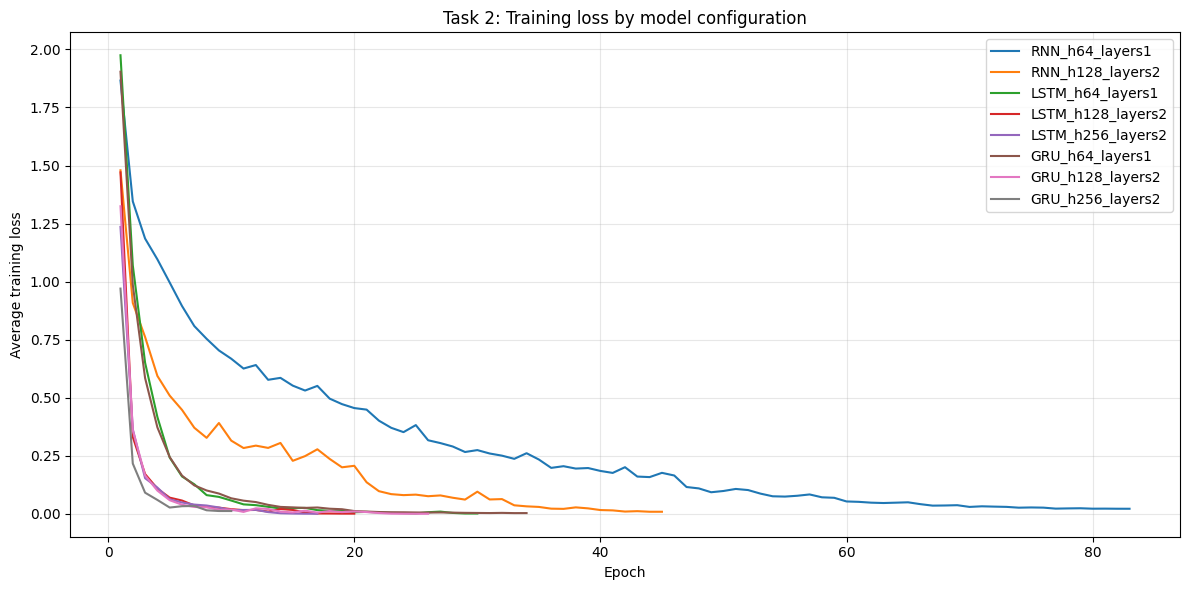

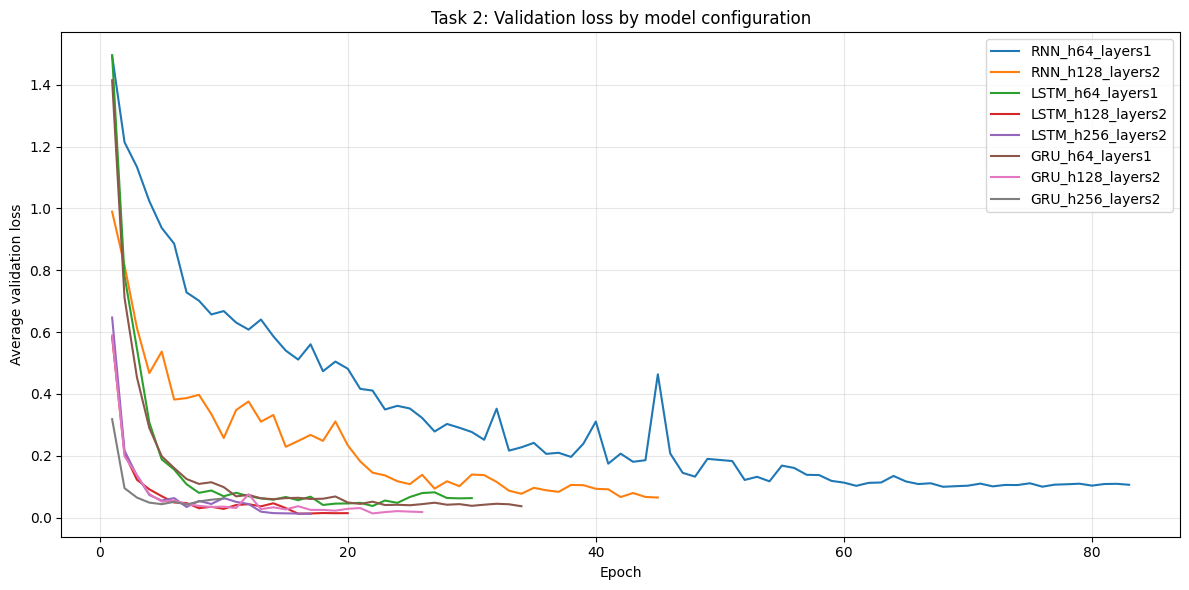

In [ ]:
plt.figure(figsize=(12, 6))
for name, history in histories.items():
    plt.plot(range(1, len(history["train_loss"]) + 1), history["train_loss"], label=name)
plt.xlabel("Epoch")
plt.ylabel("Average training loss")
plt.title("Task 2: Training loss by model configuration")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Optional validation-loss plot
plt.figure(figsize=(12, 6))
for name, history in histories.items():
    plt.plot(range(1, len(history["val_loss"]) + 1), history["val_loss"], label=name)
plt.xlabel("Epoch")
plt.ylabel("Average validation loss")
plt.title("Task 2: Validation loss by model configuration")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 8A. Plot average training error versus epochs for every hyperparameter configuration

For classification, the average training error rate is calculated as **1 − training accuracy**. The plot below compares the error curves for every RNN, LSTM, and GRU configuration explored above. A lower value indicates fewer training examples are being classified incorrectly.

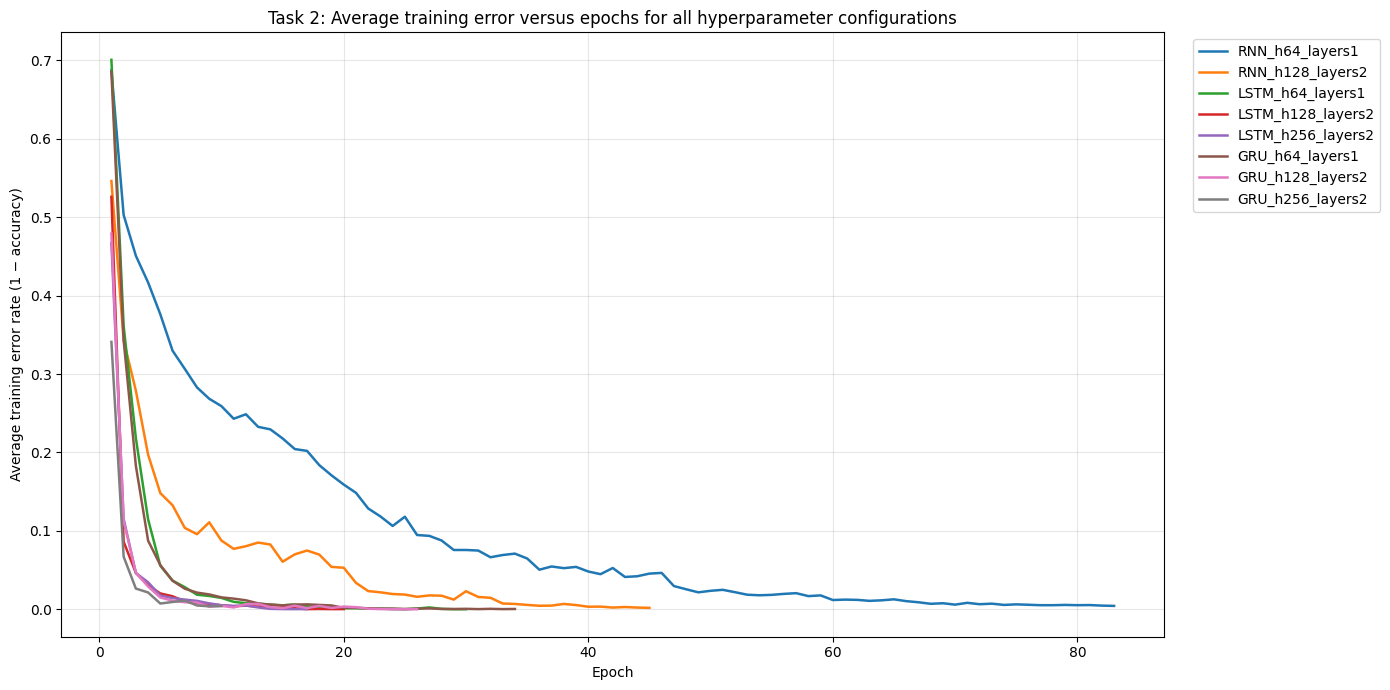

In [ ]:
# Average training error = 1 - average training accuracy
# This uses the per-epoch training accuracies saved in `histories` during model training.
plt.figure(figsize=(14, 7))

for name, history in histories.items():
    train_error = [1.0 - acc for acc in history["train_accuracy"]]
    epochs = range(1, len(train_error) + 1)
    plt.plot(epochs, train_error, label=name, linewidth=1.8)

plt.xlabel("Epoch")
plt.ylabel("Average training error rate (1 − accuracy)")
plt.title("Task 2: Average training error versus epochs for all hyperparameter configurations")
plt.grid(True, alpha=0.3)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


## 9. Best RNN, LSTM, and GRU: training/test accuracy, classification reports, and confusion matrices

This section selects the best configuration for each architecture using validation accuracy, then reports final training accuracy, test accuracy, per-digit precision/recall/F1, and the complete 10 × 10 test confusion matrix.


RNN: BEST CONFIGURATION (selected by validation accuracy)
Model: RNN_h128_layers2
Hyperparameters: hidden_size=128, num_layers=2, dropout=0.3, learning_rate=0.001
Epochs trained: 45
Validation accuracy: 0.9889 (98.89%)
Final training accuracy: 0.9995 (99.95%)
Test accuracy: 0.9300 (93.00%)

Classification report (test set):
              precision    recall  f1-score   support

           0     0.8038    0.9682    0.8784       220
           1     0.9498    0.9455    0.9476       220
           2     0.9387    0.9045    0.9213       220
           3     0.9099    0.9182    0.9140       220
           4     0.9862    0.9727    0.9794       220
           5     0.9548    0.9591    0.9569       220
           6     0.9672    0.8045    0.8784       220
           7     0.9495    0.9409    0.9452       220
           8     0.9522    0.9045    0.9277       220
           9     0.9231    0.9818    0.9515       220

    accuracy                         0.9300      2200
   macro avg     0.9335

,Predicted 0,Predicted 1,Predicted 2,Predicted 3,Predicted 4,Predicted 5,Predicted 6,Predicted 7,Predicted 8,Predicted 9
Actual 0,213,0,0,0,0,6,0,0,0,1
Actual 1,3,208,6,0,0,1,0,2,0,0
Actual 2,2,0,199,0,0,0,3,0,9,7
Actual 3,5,0,3,202,1,0,2,5,1,1
Actual 4,0,4,0,0,214,0,0,1,0,1
Actual 5,3,0,0,0,0,211,0,1,0,5
Actual 6,28,2,2,6,0,3,177,0,0,2
Actual 7,4,0,0,6,2,0,0,207,0,1
Actual 8,4,5,2,8,0,0,0,2,199,0
Actual 9,3,0,0,0,0,0,1,0,0,216


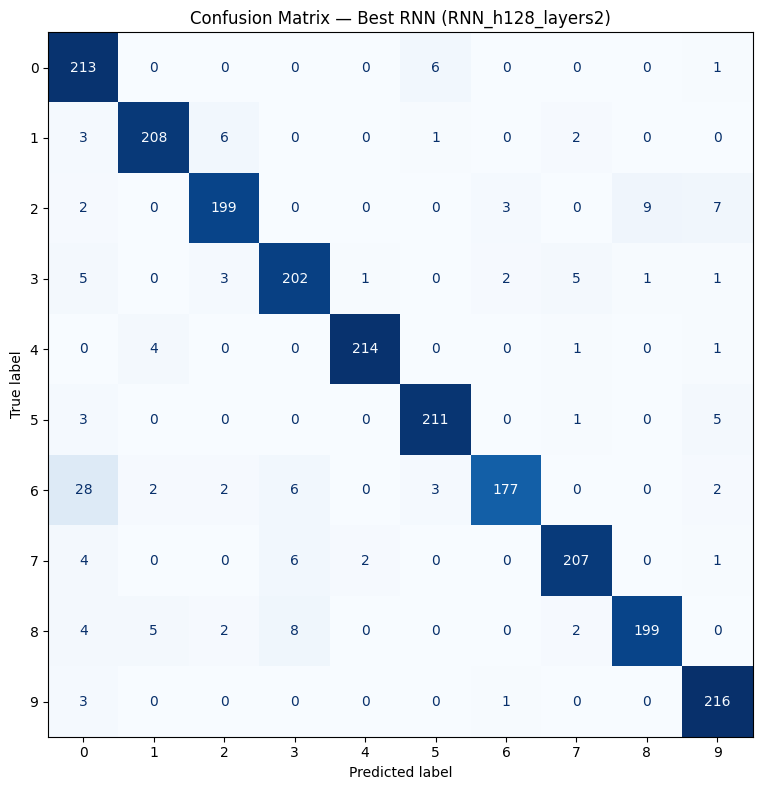


LSTM: BEST CONFIGURATION (selected by validation accuracy)
Model: LSTM_h128_layers2
Hyperparameters: hidden_size=128, num_layers=2, dropout=0.3, learning_rate=0.001
Epochs trained: 20
Validation accuracy: 0.9970 (99.70%)
Final training accuracy: 0.9995 (99.95%)
Test accuracy: 0.9664 (96.64%)

Classification report (test set):
              precision    recall  f1-score   support

           0     0.9237    0.9909    0.9561       220
           1     0.9649    1.0000    0.9821       220
           2     0.9766    0.9500    0.9631       220
           3     0.9763    0.9364    0.9559       220
           4     0.9686    0.9818    0.9752       220
           5     0.9819    0.9864    0.9841       220
           6     1.0000    0.8955    0.9448       220
           7     0.9048    0.9500    0.9268       220
           8     0.9862    0.9773    0.9817       220
           9     0.9910    0.9955    0.9932       220

    accuracy                         0.9664      2200
   macro avg     0.96

,Predicted 0,Predicted 1,Predicted 2,Predicted 3,Predicted 4,Predicted 5,Predicted 6,Predicted 7,Predicted 8,Predicted 9
Actual 0,218,0,0,0,0,0,0,2,0,0
Actual 1,0,220,0,0,0,0,0,0,0,0
Actual 2,0,0,209,0,0,0,0,10,1,0
Actual 3,1,1,2,206,4,0,0,5,1,0
Actual 4,0,0,0,0,216,3,0,1,0,0
Actual 5,0,0,0,0,1,217,0,2,0,0
Actual 6,16,0,3,0,0,1,197,1,0,2
Actual 7,1,5,0,3,1,0,0,209,1,0
Actual 8,0,2,0,2,1,0,0,0,215,0
Actual 9,0,0,0,0,0,0,0,1,0,219


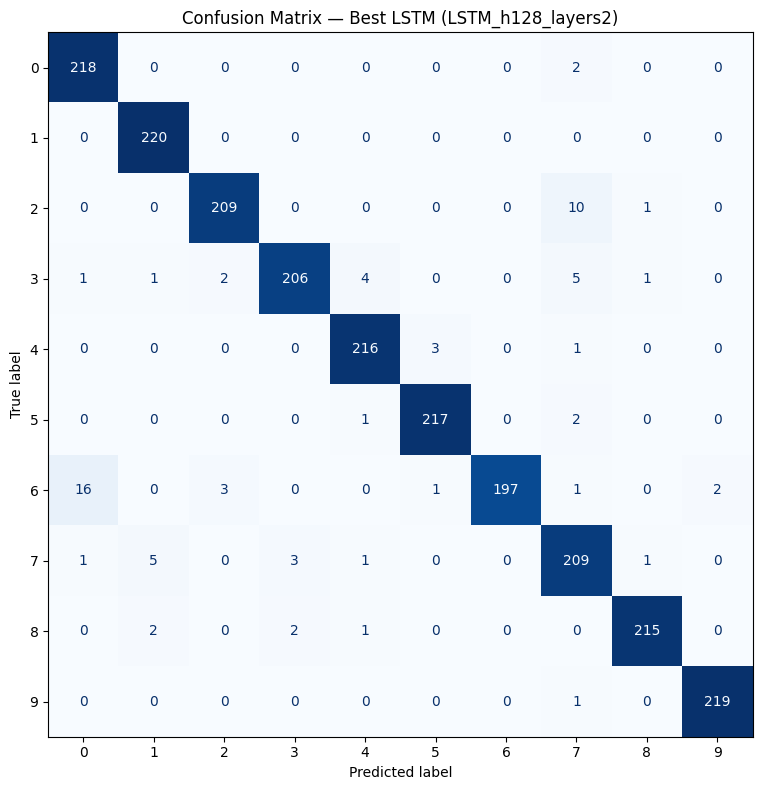


GRU: BEST CONFIGURATION (selected by validation accuracy)
Model: GRU_h128_layers2
Hyperparameters: hidden_size=128, num_layers=2, dropout=0.3, learning_rate=0.001
Epochs trained: 26
Validation accuracy: 0.9960 (99.60%)
Final training accuracy: 0.9998 (99.98%)
Test accuracy: 0.9591 (95.91%)

Classification report (test set):
              precision    recall  f1-score   support

           0     0.8417    0.9909    0.9102       220
           1     0.9910    0.9955    0.9932       220
           2     0.9954    0.9818    0.9886       220
           3     0.9279    0.9364    0.9321       220
           4     0.9636    0.9636    0.9636       220
           5     0.9646    0.9909    0.9776       220
           6     0.9947    0.8591    0.9220       220
           7     0.9500    0.9500    0.9500       220
           8     0.9902    0.9227    0.9553       220
           9     1.0000    1.0000    1.0000       220

    accuracy                         0.9591      2200
   macro avg     0.9619

,Predicted 0,Predicted 1,Predicted 2,Predicted 3,Predicted 4,Predicted 5,Predicted 6,Predicted 7,Predicted 8,Predicted 9
Actual 0,218,0,0,0,0,1,0,1,0,0
Actual 1,0,219,0,0,0,1,0,0,0,0
Actual 2,0,0,216,1,0,0,1,1,1,0
Actual 3,5,0,1,206,2,0,0,5,1,0
Actual 4,0,0,0,0,212,5,0,3,0,0
Actual 5,0,0,0,0,1,218,0,1,0,0
Actual 6,30,0,0,1,0,0,189,0,0,0
Actual 7,6,1,0,4,0,0,0,209,0,0
Actual 8,0,1,0,10,5,1,0,0,203,0
Actual 9,0,0,0,0,0,0,0,0,0,220


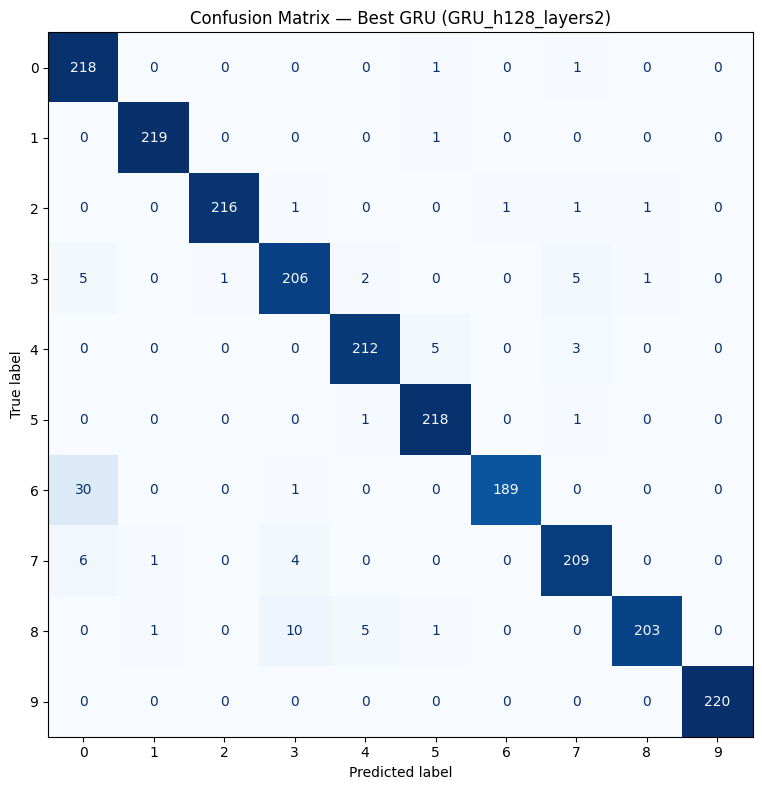


Summary: best configuration and final performance for each architecture


,architecture,model,hidden_size,num_layers,dropout,learning_rate,epochs,validation_accuracy,final_training_accuracy,test_accuracy,test_loss
0,RNN,RNN_h128_layers2,128,2,0.3,0.001,45,0.988889,0.999465,0.930000,0.411659
1,LSTM,LSTM_h128_layers2,128,2,0.3,0.001,20,0.996970,0.999465,0.966364,0.163402
2,GRU,GRU_h128_layers2,128,2,0.3,0.001,26,0.995960,0.999822,0.959091,0.192820


Saved summary and one complete confusion-matrix CSV for each available architecture.


In [ ]:
# Select the best hyperparameter configuration SEPARATELY for RNN, LSTM, and GRU.
# Selection is based on validation accuracy; test data is used only for final evaluation.
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display

best_by_architecture = (
    results_df.sort_values("validation_accuracy", ascending=False)
    .groupby("cell", sort=False)
    .head(1)
    .set_index("cell")
)

final_metrics = []
confusion_matrices = {}

for architecture in ["RNN", "LSTM", "GRU"]:
    if architecture not in best_by_architecture.index:
        print(f"No trained configuration found for {architecture}; skipping.")
        continue

    selected = best_by_architecture.loc[architecture]
    model_name = selected["model"]
    model = trained_models[model_name]

    # Evaluate the selected model on the training and held-out test sets.
    train_eval = evaluate_model(model, train_loader)
    test_eval = evaluate_model(model, test_loader)

    # Retrieve the exact hyperparameters used for this model.
    config = next(
        cfg for cfg in CONFIGS
        if f"{cfg['cell']}_h{cfg['hidden_size']}_layers{cfg['num_layers']}" == model_name
    )

    print("\n" + "=" * 90)
    print(f"{architecture}: BEST CONFIGURATION (selected by validation accuracy)")
    print("=" * 90)
    print(f"Model: {model_name}")
    print(f"Hyperparameters: hidden_size={config['hidden_size']}, "
          f"num_layers={config['num_layers']}, dropout={config['dropout']}, "
          f"learning_rate={config['lr']}")
    print(f"Epochs trained: {int(selected['epochs'])}")
    print(f"Validation accuracy: {selected['validation_accuracy']:.4f} "
          f"({selected['validation_accuracy'] * 100:.2f}%)")
    print(f"Final training accuracy: {train_eval['accuracy']:.4f} "
          f"({train_eval['accuracy'] * 100:.2f}%)")
    print(f"Test accuracy: {test_eval['accuracy']:.4f} "
          f"({test_eval['accuracy'] * 100:.2f}%)")
    print("\nClassification report (test set):")
    print(classification_report(
        test_eval["y_true"], test_eval["y_pred"],
        labels=list(range(10)),
        target_names=[str(d) for d in range(10)],
        digits=4,
        zero_division=0
    ))

    cm = confusion_matrix(
        test_eval["y_true"], test_eval["y_pred"], labels=list(range(10))
    )
    confusion_matrices[architecture] = cm

    # Print the complete numerical 10 x 10 matrix for the report.
    cm_df = pd.DataFrame(
        cm,
        index=[f"Actual {d}" for d in range(10)],
        columns=[f"Predicted {d}" for d in range(10)]
    )
    print(f"\nComplete confusion matrix — {architecture} (rows=actual, columns=predicted):")
    display(cm_df)

    # Plot each model's complete confusion matrix.
    fig, ax = plt.subplots(figsize=(9, 8))
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm, display_labels=list(range(10))
    )
    disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(f"Confusion Matrix — Best {architecture} ({model_name})")
    plt.tight_layout()
    plt.show()

    final_metrics.append({
        "architecture": architecture,
        "model": model_name,
        "hidden_size": config["hidden_size"],
        "num_layers": config["num_layers"],
        "dropout": config["dropout"],
        "learning_rate": config["lr"],
        "epochs": int(selected["epochs"]),
        "validation_accuracy": float(selected["validation_accuracy"]),
        "final_training_accuracy": float(train_eval["accuracy"]),
        "test_accuracy": float(test_eval["accuracy"]),
        "test_loss": float(test_eval["loss"])
    })

final_metrics_df = pd.DataFrame(final_metrics)
print("\nSummary: best configuration and final performance for each architecture")
display(final_metrics_df)

# Save numerical results for use in the assignment report.
final_metrics_df.to_csv("task2_best_RNN_LSTM_GRU_metrics.csv", index=False)
for architecture, cm in confusion_matrices.items():
    pd.DataFrame(
        cm,
        index=[f"Actual {d}" for d in range(10)],
        columns=[f"Predicted {d}" for d in range(10)]
    ).to_csv(f"task2_{architecture.lower()}_confusion_matrix.csv", index=True)

print("Saved summary and one complete confusion-matrix CSV for each available architecture.")


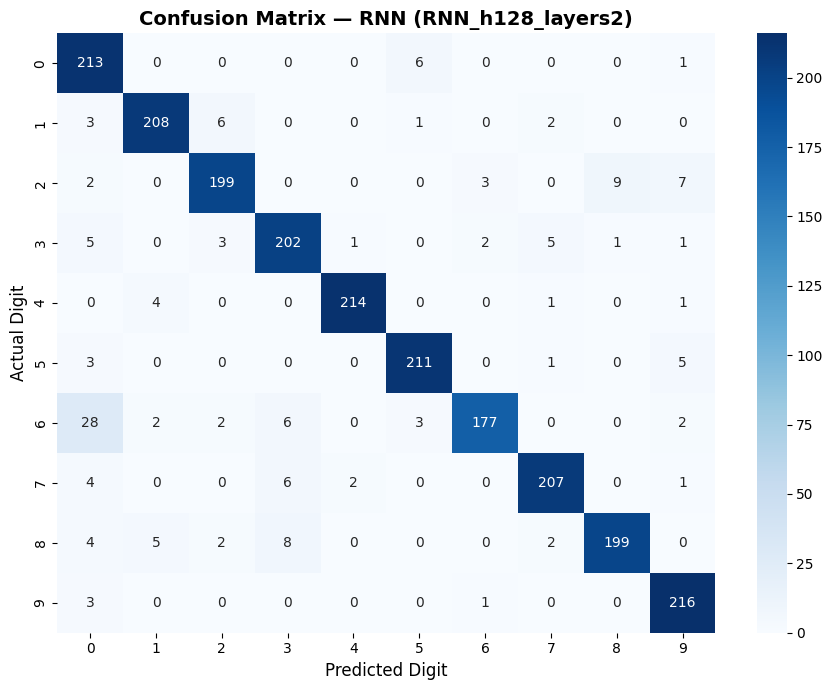

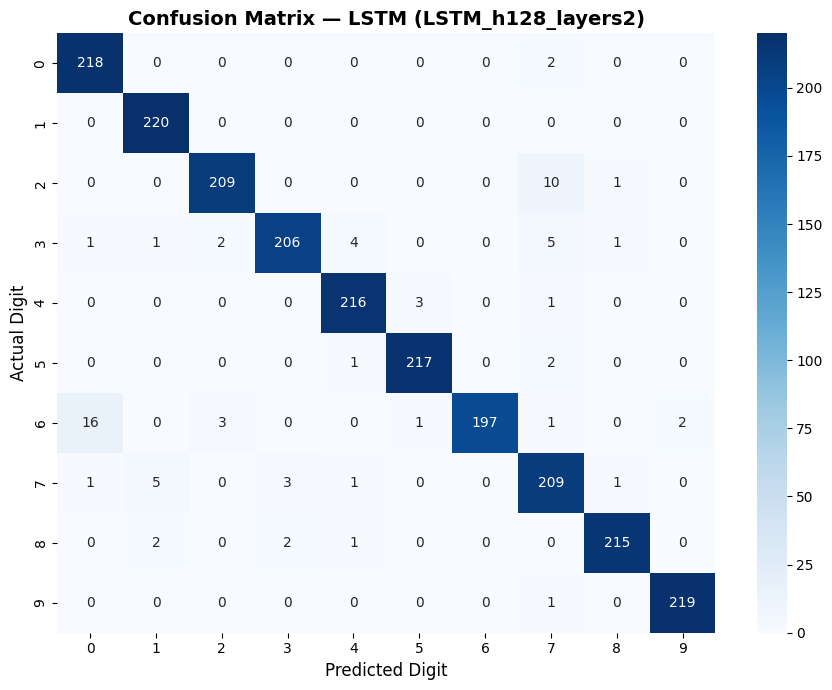

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Evaluate and plot RNN (RNN_h128_layers2)
rnn_model = trained_models["RNN_h128_layers2"]
rnn_eval = evaluate_model(rnn_model, test_loader)
y_true_rnn = rnn_eval["y_true"]
y_pred_rnn = rnn_eval["y_pred"]
cm_rnn = confusion_matrix(y_true_rnn, y_pred_rnn, labels=list(range(10)))

plt.figure(figsize=(9, 7))
sns.heatmap(cm_rnn, annot=True, fmt="d", cmap="Blues", cbar=True,
            xticklabels=list(range(10)), yticklabels=list(range(10)))
plt.title("Confusion Matrix — RNN (RNN_h128_layers2)", fontsize=14, fontweight='bold')
plt.xlabel("Predicted Digit", fontsize=12)
plt.ylabel("Actual Digit", fontsize=12)
plt.tight_layout()
plt.show()

# Evaluate and plot LSTM (LSTM_h128_layers2)
lstm_model = trained_models["LSTM_h128_layers2"]
lstm_eval = evaluate_model(lstm_model, test_loader)
y_true_lstm = lstm_eval["y_true"]
y_pred_lstm = lstm_eval["y_pred"]
cm_lstm = confusion_matrix(y_true_lstm, y_pred_lstm, labels=list(range(10)))

plt.figure(figsize=(9, 7))
sns.heatmap(cm_lstm, annot=True, fmt="d", cmap="Blues", cbar=True,
            xticklabels=list(range(10)), yticklabels=list(range(10)))
plt.title("Confusion Matrix — LSTM (LSTM_h128_layers2)", fontsize=14, fontweight='bold')
plt.xlabel("Predicted Digit", fontsize=12)
plt.ylabel("Actual Digit", fontsize=12)
plt.tight_layout()
plt.show()

## 10. Visualize MFCC heatmaps for representative utterances

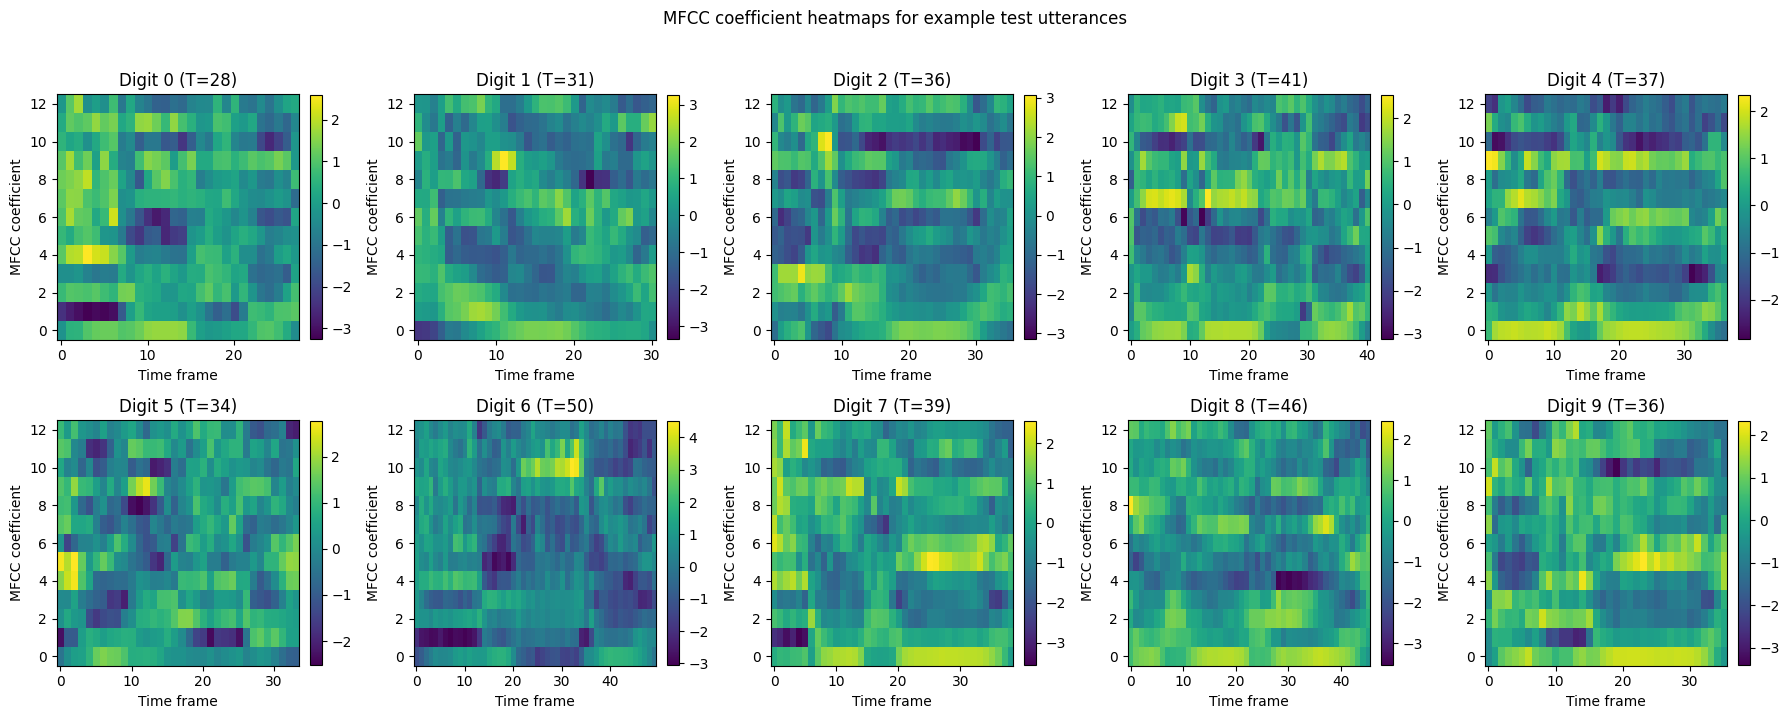

In [ ]:
def plot_mfcc_heatmaps(sequences, labels, digits_to_show=range(10)):
    fig, axes = plt.subplots(2, 5, figsize=(18, 7))
    axes = axes.ravel()

    for ax, digit in zip(axes, digits_to_show):
        indices = np.where(np.asarray(labels) == digit)[0]
        if len(indices) == 0:
            ax.set_title(f"Digit {digit}: no sample")
            ax.axis("off")
            continue

        seq = sequences[int(indices[0])]
        image = ax.imshow(seq.T, aspect="auto", origin="lower", interpolation="nearest")
        ax.set_title(f"Digit {digit} (T={len(seq)})")
        ax.set_xlabel("Time frame")
        ax.set_ylabel("MFCC coefficient")
        fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)

    plt.suptitle("MFCC coefficient heatmaps for example test utterances", y=1.02)
    plt.tight_layout()
    plt.show()

plot_mfcc_heatmaps(X_test, y_test)

## 11. Save the experiment table

In [ ]:
results_df.to_csv("task2_results.csv", index=False)
print("Saved results to task2_results.csv")

Saved results to task2_results.csv


## 12. Notes for the report

- **Final model comparison:** Section 9 selects the best RNN, LSTM, and GRU configuration separately using validation accuracy. It reports final training accuracy, test accuracy, per-digit precision/recall/F1, and a complete 10 × 10 confusion matrix for each available architecture. LSTM has gates that can help preserve information over longer sequences; a vanilla RNN can have more difficulty learning long-range dependencies.
- **GRU:** an optional bonus model. It also uses gates but has a simpler structure than LSTM.
- **Padding:** batches need a common time dimension. `pad_sequence` adds zeros to shorter utterances within a batch.
- **Packing:** `pack_padded_sequence` tells the recurrent layer the true length of each utterance, so padded frames are not treated as real speech frames.
- **Convergence:** the requested condition is `abs(current_training_loss - previous_training_loss) < 1e-4`. The notebook also has a validation-based patience safety stop and a maximum epoch cap; mention these clearly in your report if either safety condition ends a run.
- **Speaker split:** the UCI documentation states the test speakers are different from the training speakers, so the supplied test file is kept separate from training and validation.
- **Reproducibility:** report the configurations you actually ran and the results produced by your notebook. Do not invent or copy example accuracies.